## Eksperimen v2

Output tersimpan dari training 50 epoch. Mode bawaan memuat checkpoint terbaik untuk evaluasi ulang. Checkpoint kandidat epoch 15, 30, dan 50 tersimpan di folder run v2.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST
from torchvision.utils import make_grid
from torchmetrics.image.fid import FrechetInceptionDistance

TRAIN = False
FID_BATCH = 32
SEED, BATCH, FID_N = 42, 128, 2048
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CKPT_DIR, METRIC_DIR = ROOT / "results/checkpoints/custom_vanilla_gan_v2", ROOT / "results/metrics/custom_vanilla_gan_v2"
if TRAIN and any(CKPT_DIR.glob("epoch-*.pt")):
    raise FileExistsError("Run v2 sudah memiliki checkpoint kandidat. Untuk evaluasi, pilih TRAIN=False.")
if not TRAIN and not (CKPT_DIR / "vanilla_gan_best.pt").is_file():
    raise FileNotFoundError("Checkpoint run v2 belum tersedia.")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
METRIC_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED); np.random.seed(SEED)

train_raw = FashionMNIST(ROOT / "data", train=True, download=True)
test_raw = FashionMNIST(ROOT / "data", train=False, download=True)
images = torch.cat([train_raw.data, test_raw.data]).unsqueeze(1)
labels = torch.cat([train_raw.targets, test_raw.targets])

with np.load(ROOT / "results/metrics/fashion_mnist_seed42.npz") as f:
    splits = {k: TensorDataset(images[f[k]].float().div_(255), labels[f[k]]) for k in ("train", "val", "test")}

if TRAIN:
    train_images, train_labels = splits["train"].tensors
    train_rng = torch.Generator().manual_seed(SEED)

def train_batches():
    order = torch.randperm(len(train_images), generator=train_rng)
    for batch_ids in order.split(BATCH):
        yield train_images[batch_ids], train_labels[batch_ids]


In [2]:
class VanillaGAN(nn.Module):
    def __init__(self):
        super().__init__()
        self.generator = nn.Sequential(nn.Linear(100, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(), nn.Linear(512, 784), nn.Tanh(), nn.Unflatten(1, (1, 28, 28)))
        self.discriminator = nn.Sequential(nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2), nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Linear(256, 1))

class ValExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU())
        self.head = nn.Linear(128, 10)
    def forward(self, x):
        return self.head(self.net(x))

def frechet_cnn(model, ext, mu_r, sig_r):
    rng = torch.Generator(device=DEVICE).manual_seed(SEED)
    with torch.inference_mode():
        feats = ext.net((model.generator(torch.randn((1024, 100), device=DEVICE, generator=rng)) + 1) / 2).cpu().numpy().astype(np.float64)
    mu_f, sig_f = feats.mean(0), np.cov(feats, rowvar=False) + np.eye(feats.shape[1]) * 1e-6
    vals_r, vecs_r = np.linalg.eigh(sig_r)
    root_r = (vecs_r * np.sqrt(np.clip(vals_r, 0.0, None))) @ vecs_r.T
    middle = root_r @ sig_f @ root_r
    eigenvalues = np.linalg.eigvalsh((middle + middle.T) / 2)
    trace_root = np.sqrt(np.clip(eigenvalues, 0.0, None)).sum()
    delta = mu_r - mu_f
    score = float(delta @ delta + np.trace(sig_r + sig_f) - 2 * trace_root)
    if not np.isfinite(score) or score < -1e-8:
        raise FloatingPointError(f"Invalid validation CNN-FID: {score}")
    return max(0.0, score)

model = VanillaGAN().to(DEVICE)
chosen = {}

if TRAIN:
    ext = ValExtractor().to(DEVICE)
    opt_e = torch.optim.Adam(ext.parameters(), lr=1e-3)
    for _ in range(3):
        for bx, by in train_batches():
            loss = F.cross_entropy(ext(bx.to(DEVICE)), by.to(DEVICE))
            opt_e.zero_grad(set_to_none=True); loss.backward(); opt_e.step()
    ext.eval()
    with torch.inference_mode():
        rf = torch.cat([ext.net(b.to(DEVICE)).cpu() for b in splits["val"].tensors[0].split(256)]).numpy().astype(np.float64)
    mu_r, sig_r = rf.mean(0), np.cov(rf, rowvar=False) + np.eye(rf.shape[1]) * 1e-6

    opt_g = torch.optim.Adam(model.generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(model.discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    best, hist = float("inf"), []
    for epoch in range(1, 51):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        started = time.perf_counter()
        model.train()
        d_sum, g_sum, n = 0.0, 0.0, 0
        for x, _ in train_batches():
            x = 2 * x.to(DEVICE) - 1
            fake = model.generator(torch.randn(len(x), 100, device=DEVICE))
            r_out, f_out = model.discriminator(x), model.discriminator(fake.detach())
            loss_d = F.binary_cross_entropy_with_logits(r_out, torch.ones_like(r_out)) + F.binary_cross_entropy_with_logits(f_out, torch.zeros_like(f_out))
            opt_d.zero_grad(set_to_none=True); loss_d.backward(); opt_d.step()
            g_out = model.discriminator(fake)
            loss_g = F.binary_cross_entropy_with_logits(g_out, torch.ones_like(g_out))
            opt_g.zero_grad(set_to_none=True); loss_g.backward(); opt_g.step()
            d_sum += loss_d.item() * len(x); g_sum += loss_g.item() * len(x); n += len(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        train_seconds = time.perf_counter() - started
        assert n == len(splits["train"])
        val_s = None
        if epoch in (15, 30, 50):
            model.eval()
            val_s = frechet_cnn(model, ext, mu_r, sig_r)
            candidate = {
                "epoch": epoch,
                "val_cnn_fid": val_s,
                "model_state_dict": {k: v.cpu().clone() for k, v in model.state_dict().items()},
                "seed": SEED,
            }
            torch.save(candidate, CKPT_DIR / f"epoch-{epoch:03d}.pt")
            if val_s < best:
                best, chosen["Vanilla GAN"] = val_s, epoch
                best_w = candidate["model_state_dict"]
                torch.save(candidate, CKPT_DIR / "vanilla_gan_best.pt")
        hist.append({"epoch": epoch, "d_loss": d_sum / n, "g_loss": g_sum / n, "train_seconds": train_seconds, "val_cnn_fid": val_s})
        if epoch % 5 == 0 or epoch == 1:
            print(f"[Vanilla GAN] Epoch {epoch:02d}/50 | D: {d_sum/n:.4f} | G: {g_sum/n:.4f} | Val CNN-FID: {val_s}")
    model.load_state_dict(best_w)
    pd.DataFrame(hist).to_csv(METRIC_DIR / "vanilla_gan_history.csv", index=False)
    (METRIC_DIR / "selected_epoch.json").write_text(json.dumps(chosen, indent=2))
else:
    ckpt = torch.load(CKPT_DIR / "vanilla_gan_best.pt", map_location="cpu", weights_only=True)
    model.load_state_dict(ckpt["model_state_dict"]); model.eval(); chosen["Vanilla GAN"] = ckpt["epoch"]

display(pd.Series(chosen, name="Epoch terpilih").to_frame())

[Vanilla GAN] Epoch 01/50 | D: 0.4370 | G: 2.6801 | Val CNN-FID: None
[Vanilla GAN] Epoch 05/50 | D: 0.5811 | G: 3.0526 | Val CNN-FID: None
[Vanilla GAN] Epoch 10/50 | D: 0.8061 | G: 2.0604 | Val CNN-FID: None
[Vanilla GAN] Epoch 15/50 | D: 0.9302 | G: 1.7368 | Val CNN-FID: 109.1161473800812
[Vanilla GAN] Epoch 20/50 | D: 1.0209 | G: 1.5456 | Val CNN-FID: None
[Vanilla GAN] Epoch 25/50 | D: 1.0936 | G: 1.3827 | Val CNN-FID: None
[Vanilla GAN] Epoch 30/50 | D: 1.1336 | G: 1.2288 | Val CNN-FID: 47.854073524439514
[Vanilla GAN] Epoch 35/50 | D: 1.1745 | G: 1.1440 | Val CNN-FID: None
[Vanilla GAN] Epoch 40/50 | D: 1.1967 | G: 1.0649 | Val CNN-FID: None
[Vanilla GAN] Epoch 45/50 | D: 1.2081 | G: 1.0513 | Val CNN-FID: None
[Vanilla GAN] Epoch 50/50 | D: 1.2344 | G: 0.9977 | Val CNN-FID: 24.158933990569494
             Epoch terpilih
Vanilla GAN              50


Vanilla GAN Test FID (TorchMetrics, N=2048): 117.9728 | Latensi Batch 64: 0.353 ms


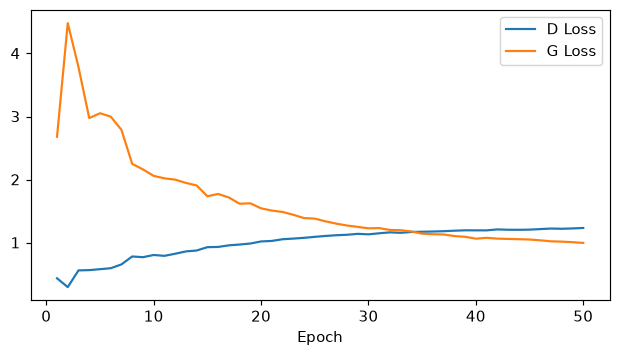

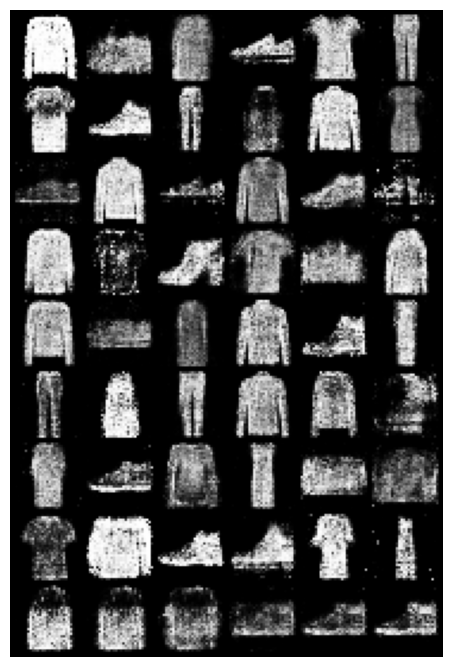

In [3]:
@torch.inference_mode()
def calc_fid_tm(real_x, fake_x):
    weights = ROOT / "data/torch-cache/weights-inception-2015-12-05-6726825d.pth"
    fid = FrechetInceptionDistance(feature=2048, normalize=True, antialias=True,
                                   feature_extractor_weights_path=str(weights)).to(DEVICE).eval()
    for b in real_x.split(FID_BATCH): fid.update(b.to(DEVICE).repeat(1, 3, 1, 1), real=True)
    for b in fake_x.split(FID_BATCH): fid.update(b.to(DEVICE).repeat(1, 3, 1, 1), real=False)
    return float(fid.compute())

def calc_latency(fn, runs=30):
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    for _ in range(5): fn()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs): fn()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) * 1000.0 / runs

test_x = splits["test"].tensors[0]
with torch.inference_mode():
    rng = torch.Generator(device=DEVICE).manual_seed(SEED)
    noise = torch.randn((FID_N, 100), device=DEVICE, generator=rng)
    gen_samples = torch.cat([((model.generator(z) + 1) / 2).cpu() for z in noise.split(BATCH)])
    fid_test = calc_fid_tm(test_x[:FID_N], gen_samples)
    lat_ms = calc_latency(lambda: (model.generator(torch.randn((64, 100), device=DEVICE)) + 1) / 2)

    rng_i = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
    z_a, z_b = torch.randn((1, 100), device=DEVICE, generator=rng_i), torch.randn((1, 100), device=DEVICE, generator=rng_i)
    alphas = torch.linspace(0.0, 1.0, 6, device=DEVICE).unsqueeze(1)
    interp = ((model.generator((1 - alphas) * z_a + alphas * z_b) + 1) / 2).cpu()

pd.DataFrame([{"Model": "Vanilla GAN", "Epoch": chosen["Vanilla GAN"], "FID Test (N=2048)": fid_test, "Latensi Batch 64 (ms)": lat_ms}]).to_csv(METRIC_DIR / "vanilla_gan_eval.csv", index=False)
print(f"Vanilla GAN Test FID (TorchMetrics, N={FID_N}): {fid_test:.4f} | Latensi Batch 64: {lat_ms:.3f} ms")

hdf = pd.read_csv(METRIC_DIR / "vanilla_gan_history.csv")
plt.figure(figsize=(6, 3.5)); plt.plot(hdf["epoch"], hdf["d_loss"], label="D Loss"); plt.plot(hdf["epoch"], hdf["g_loss"], label="G Loss"); plt.xlabel("Epoch"); plt.legend(); plt.tight_layout(); plt.show()
np.savez_compressed(METRIC_DIR / "vanilla_gan_visuals.npz", samples=gen_samples[:16].numpy(),
                    interpolation=interp.numpy())
plt.figure(figsize=(6, 8)); plt.imshow(make_grid(torch.cat([gen_samples[:48].cpu(), interp]), nrow=6, padding=2).permute(1, 2, 0).numpy()); plt.axis("off"); plt.show()